<a href="https://colab.research.google.com/github/mazenkoz/artificial-intelligence-coursework/blob/flowers-travel-update/Task3_AIAgent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN6005 – Task 3: AI Agent Design and Implementation
**Agent type:** Travel Information Agent

A Python agent that answers travel questions about five European cities. It searches a small predefined knowledge base, sends the most relevant entries to an LLM (Qwen2.5-1.5B-Instruct), and returns the answer with its sources. Sections follow the brief (3.1–3.3); the full explanations are in the report (sections 4.1–4.4).

### Setup
Install and import the libraries, fix the random seed (42) and create a `screenshots/` folder. A GPU runtime (T4) is recommended for the LLM.

In [ ]:
%pip -q install sentence-transformers transformers accelerate

import re, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

random.seed(42); np.random.seed(42); torch.manual_seed(42)
output_dir = Path("screenshots"); output_dir.mkdir(exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 3.1 Agent Design

### 3.1.1 Knowledge source
A small knowledge base written by the group: 26 entries covering London, Paris, Rome, Barcelona and Amsterdam (airport transfers, public transport, attractions, money and practical tips), plus one entry describing what the agent covers.

In [ ]:
KB = [
 # ---------------- London
 ("LON-1", "London", "Getting from the airport",
  "London's main airports are Heathrow, Gatwick, Stansted, Luton and London City. From Heathrow, the Elizabeth line and the Piccadilly line (Underground) go to central London, and the Heathrow Express reaches Paddington in about 15 minutes. From Gatwick, the Gatwick Express goes to Victoria in about 30 minutes."),
 ("LON-2", "London", "Public transport",
  "London has the Underground (the Tube), buses, the Overground, the Elizabeth line and the DLR. The easiest way to pay is with a contactless bank card or an Oyster card, and daily fares are capped so you never pay more than a set amount per day. Buses do not accept cash."),
 ("LON-3", "London", "Top attractions",
  "Popular sights include the British Museum, the Tower of London, Buckingham Palace, Westminster Abbey, the London Eye and the Natural History Museum. Many of London's major museums, such as the British Museum and the Natural History Museum, are free to enter."),
 ("LON-4", "London", "Money, plugs and tipping",
  "The UK uses the pound sterling (GBP). Plugs are type G (three rectangular pins) and the voltage is 230V. Cards are accepted almost everywhere. In restaurants a tip of about 10–12.5% is normal and is often already added as a service charge."),
 ("LON-5", "London", "Practical tips",
  "The emergency number in the UK is 999 (112 also works). English is spoken. The weather changes quickly, so carry an umbrella, and summer is the busiest time to visit."),
 # ---------------- Paris
 ("PAR-1", "Paris", "Getting from the airport",
  "Paris has two main airports: Charles de Gaulle (CDG) and Orly. From CDG, the RER B train goes to Gare du Nord and Châtelet, and the Roissybus goes to Opéra. From Orly, metro line 14 runs directly into central Paris, or you can take the Orlyval shuttle to connect with the RER B."),
 ("PAR-2", "Paris", "Public transport",
  "Paris has the Métro, the RER suburban trains, buses and trams. Single tickets can be loaded onto a Navigo Easy card or bought in the Île-de-France Mobilités app, and visitors staying a week can use the weekly Navigo Découverte pass."),
 ("PAR-3", "Paris", "Top attractions",
  "Top sights include the Eiffel Tower, the Louvre, the Musée d'Orsay, Notre-Dame Cathedral, the Arc de Triomphe and Montmartre with the Sacré-Cœur basilica. It is best to book timed tickets for the Louvre and the Eiffel Tower in advance."),
 ("PAR-4", "Paris", "Money, plugs and tipping",
  "France uses the euro (EUR). Plugs are types C and E and the voltage is 230V. Service is included in restaurant bills ('service compris'), so tipping is optional, although leaving a little extra for good service is common."),
 ("PAR-5", "Paris", "Practical tips",
  "The European emergency number 112 works in France. French is the main language and greeting staff with 'Bonjour' is appreciated. Many museums close one day a week: the Louvre is closed on Tuesdays and the Musée d'Orsay on Mondays."),
 # ---------------- Rome
 ("ROM-1", "Rome", "Getting from the airport",
  "Rome's main airport is Fiumicino (Leonardo da Vinci), with a smaller airport at Ciampino. From Fiumicino, the Leonardo Express train goes non-stop to Roma Termini in about 32 minutes. From Ciampino, shuttle buses run to Termini station."),
 ("ROM-2", "Rome", "Public transport",
  "Rome has three metro lines (A, B and C), plus buses and trams. A standard BIT ticket is valid for 100 minutes, and contactless bank cards can be used at metro gates. Paper tickets must be validated when you board. In the historic centre, walking is often the quickest option."),
 ("ROM-3", "Rome", "Top attractions",
  "Must-see sights include the Colosseum and Roman Forum, the Vatican Museums and Sistine Chapel, St Peter's Basilica, the Pantheon, the Trevi Fountain and the Spanish Steps. Tickets for the Colosseum and the Vatican Museums should be booked in advance."),
 ("ROM-4", "Rome", "Money, plugs and tipping",
  "Italy uses the euro (EUR). Plugs are types C, F and L and the voltage is 230V. Tipping is not expected, and many restaurants add a small cover charge called 'coperto' to the bill."),
 ("ROM-5", "Rome", "Practical tips",
  "The emergency number is 112. Italian is the main language. Churches, including St Peter's Basilica, require shoulders and knees to be covered. Summer in Rome is very hot, so spring and autumn are the most comfortable times to visit."),
 # ---------------- Barcelona
 ("BCN-1", "Barcelona", "Getting from the airport",
  "Barcelona's airport is Josep Tarradellas Barcelona-El Prat (BCN). The Aerobús runs to Plaça de Catalunya, metro line L9 Sud connects both terminals to the city, and the R2 Nord train runs from Terminal 2 to the city centre."),
 ("BCN-2", "Barcelona", "Public transport",
  "Barcelona has a metro, buses, trams and FGC trains. The T-casual ticket gives 10 journeys, and the Hola Barcelona travel card offers unlimited travel for tourists for two to five days."),
 ("BCN-3", "Barcelona", "Top attractions",
  "Highlights include the Sagrada Família, Park Güell, Casa Batlló, La Rambla, the Gothic Quarter and Barceloneta beach. The Sagrada Família and Park Güell use timed tickets that should be booked in advance."),
 ("BCN-4", "Barcelona", "Money, plugs and tipping",
  "Spain uses the euro (EUR). Plugs are types C and F and the voltage is 230V. Tipping is optional, and rounding up or leaving a small amount for good service is common."),
 ("BCN-5", "Barcelona", "Practical tips",
  "The emergency number is 112. Both Catalan and Spanish are spoken. Pickpocketing is common around La Rambla and on the metro, so keep valuables safe. People usually eat dinner late, often around 9pm."),
 # ---------------- Amsterdam
 ("AMS-1", "Amsterdam", "Getting from the airport",
  "Amsterdam's airport is Schiphol (AMS). Trains from Schiphol reach Amsterdam Centraal in about 15–20 minutes, and bus 397 runs to Museumplein and Leidseplein."),
 ("AMS-2", "Amsterdam", "Public transport",
  "GVB runs Amsterdam's trams, metro, buses and ferries. You can tap in and out with a contactless bank card or buy a GVB day ticket. Cycling is very popular, so watch out for bikes and never walk in bike lanes."),
 ("AMS-3", "Amsterdam", "Top attractions",
  "Top sights include the Rijksmuseum, the Van Gogh Museum, the Anne Frank House, a canal cruise, Vondelpark and the Jordaan area. Tickets for the Anne Frank House are only sold online and often sell out, so book early."),
 ("AMS-4", "Amsterdam", "Money, plugs and tipping",
  "The Netherlands uses the euro (EUR). Plugs are types C and F and the voltage is 230V. Many shops and cafés are card-only. Tipping is optional, with around 5–10% for good service."),
 ("AMS-5", "Amsterdam", "Practical tips",
  "The emergency number is 112. Dutch is the main language, but English is very widely spoken. In spring (around March to May) the Keukenhof tulip gardens near Amsterdam are a popular day trip."),
 # ---------------- About the agent
 ("GEN-1", "General", "What this agent covers",
  "This travel information agent covers five European cities: London, Paris, Rome, Barcelona and Amsterdam. For each city it can answer questions about getting from the airport, public transport, top attractions, money, plugs and tipping, and practical tips. It does not have live information such as weather, prices or bookings."),
]
kb = pd.DataFrame(KB, columns=["id", "city", "topic", "text"])
pd.set_option("display.max_colwidth", 90)
print("Knowledge base entries:", len(kb))
display(kb[["id", "city", "topic", "text"]])
kb.to_csv(output_dir / "task3_knowledge_base.csv", index=False)

Knowledge base entries: 26


,id,city,topic,text
0,LON-1,London,Getting from the airport,"London's main airports are Heathrow, Gatwick, Stansted, Luton and London City. From He..."
1,LON-2,London,Public transport,"London has the Underground (the Tube), buses, the Overground, the Elizabeth line and t..."
2,LON-3,London,Top attractions,"Popular sights include the British Museum, the Tower of London, Buckingham Palace, Wes..."
3,LON-4,London,"Money, plugs and tipping",The UK uses the pound sterling (GBP). Plugs are type G (three rectangular pins) and th...
4,LON-5,London,Practical tips,The emergency number in the UK is 999 (112 also works). English is spoken. The weather...
5,PAR-1,Paris,Getting from the airport,"Paris has two main airports: Charles de Gaulle (CDG) and Orly. From CDG, the RER B tra..."
6,PAR-2,Paris,Public transport,"Paris has the Métro, the RER suburban trains, buses and trams. Single tickets can be l..."
7,PAR-3,Paris,Top attractions,"Top sights include the Eiffel Tower, the Louvre, the Musée d'Orsay, Notre-Dame Cathedr..."
8,PAR-4,Paris,"Money, plugs and tipping",France uses the euro (EUR). Plugs are types C and E and the voltage is 230V. Service i...
9,PAR-5,Paris,Practical tips,The European emergency number 112 works in France. French is the main language and gre...


### 3.1.2 Architecture
How a question flows through the agent: city memory → knowledge base search → decision (answer or decline) → LLM → answer with sources.

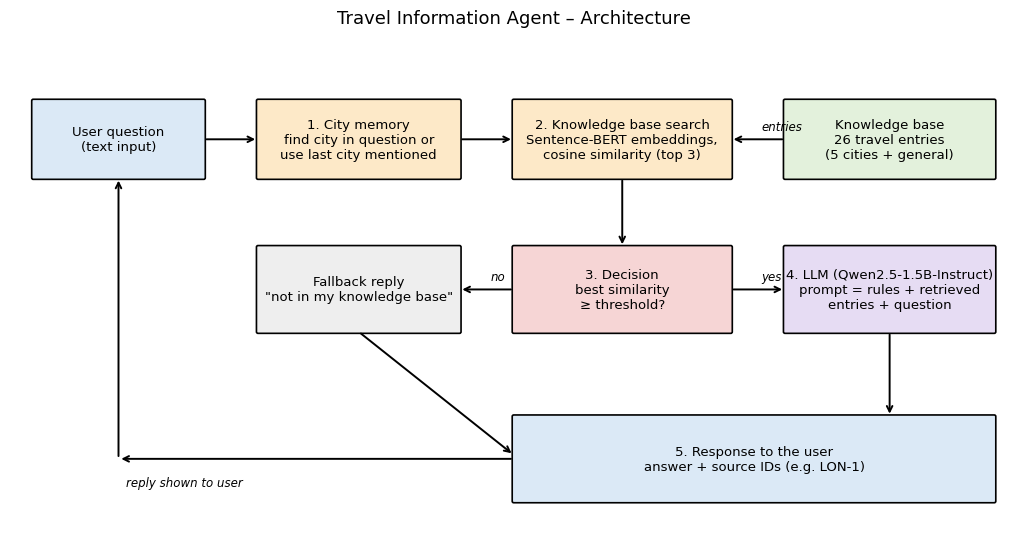

In [ ]:
from matplotlib.patches import FancyBboxPatch

def box(ax, xy, w, h, text, color):
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02", fc=color, ec="black", lw=1.2))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center", fontsize=9.5, wrap=True)

def arrow(ax, start, end, label=""):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.4))
    if label:
        ax.text((start[0] + end[0]) / 2 + 0.05, (start[1] + end[1]) / 2 + 0.12, label, fontsize=8.5, style="italic")

fig, ax = plt.subplots(figsize=(13, 6.5)); ax.set_xlim(0, 13); ax.set_ylim(0, 6.5); ax.axis("off")
box(ax, (0.3, 4.6), 2.2, 1.0, "User question\n(text input)", "#dbe9f6")
box(ax, (3.2, 4.6), 2.6, 1.0, "1. City memory\nfind city in question or\nuse last city mentioned", "#fde9c8")
box(ax, (6.5, 4.6), 2.8, 1.0, "2. Knowledge base search\nSentence-BERT embeddings,\ncosine similarity (top 3)", "#fde9c8")
box(ax, (10.0, 4.6), 2.7, 1.0, "Knowledge base\n26 travel entries\n(5 cities + general)", "#e3f1dc")
box(ax, (6.5, 2.6), 2.8, 1.1, "3. Decision\nbest similarity\n≥ threshold?", "#f6d5d5")
box(ax, (10.0, 2.6), 2.7, 1.1, "4. LLM (Qwen2.5-1.5B-Instruct)\nprompt = rules + retrieved\nentries + question", "#e6dcf3")
box(ax, (3.2, 2.6), 2.6, 1.1, "Fallback reply\n\"not in my knowledge base\"", "#eeeeee")
box(ax, (6.5, 0.4), 6.2, 1.1, "5. Response to the user\nanswer + source IDs (e.g. LON-1)", "#dbe9f6")
arrow(ax, (2.5, 5.1), (3.2, 5.1)); arrow(ax, (5.8, 5.1), (6.5, 5.1))
arrow(ax, (10.0, 5.1), (9.3, 5.1), "entries"); arrow(ax, (7.9, 4.6), (7.9, 3.7))
arrow(ax, (9.3, 3.15), (10.0, 3.15), "yes"); arrow(ax, (6.5, 3.15), (5.8, 3.15), "no")
arrow(ax, (11.35, 2.6), (11.35, 1.5)); arrow(ax, (4.5, 2.6), (6.5, 1.0))
arrow(ax, (6.5, 0.95), (1.4, 0.95)); arrow(ax, (1.4, 0.95), (1.4, 4.6))
ax.text(1.5, 0.6, "reply shown to user", fontsize=8.5, style="italic")
ax.set_title("Travel Information Agent – Architecture", fontsize=13)
plt.savefig(output_dir / "task3_01_agent_architecture.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.2 Agent Implementation

### 3.2.1 Knowledge base search
Each entry is turned into a Sentence-BERT embedding. A question is embedded the same way, and the most similar entries are found with cosine similarity.

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2", device=device)
kb_texts = (kb["city"] + " – " + kb["topic"] + ": " + kb["text"]).tolist()
kb_emb = embedder.encode(kb_texts, normalize_embeddings=True)
print("Knowledge base embeddings:", kb_emb.shape)

def search_kb(query, city=None, top_k=3):
    """Return the top_k most similar entries (only that city + general entries if a city is known)."""
    q = embedder.encode([query], normalize_embeddings=True)[0]
    scores = kb_emb @ q                                   # cosine similarity (vectors are normalised)
    allowed = np.ones(len(kb), bool) if city is None else kb["city"].isin([city, "General"]).values
    scores = np.where(allowed, scores, -1)
    best = np.argsort(scores)[::-1][:top_k]
    return [(kb.loc[i, "id"], float(scores[i]), kb.loc[i, "text"]) for i in best]

for q in ["How do I get from Heathrow to the city?", "Is tipping expected in Rome?"]:
    print("\nQ:", q)
    for kb_id, score, _ in search_kb(q):
        print(f"   {kb_id}  similarity={score:.3f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Knowledge base embeddings: (26, 384)

Q: How do I get from Heathrow to the city?
   LON-1  similarity=0.605
   LON-2  similarity=0.437
   LON-3  similarity=0.307

Q: Is tipping expected in Rome?
   ROM-4  similarity=0.596
   ROM-2  similarity=0.410
   ROM-5  similarity=0.404


### 3.2.2 Loading the LLM
Qwen2.5-1.5B-Instruct is a small open instruction-tuned model that runs on a free Colab GPU without an API key.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device)
llm.eval()
print("Loaded", MODEL_NAME, "on", device)

def ask_llm(messages, max_new_tokens=180):
    """Send chat messages to the LLM and return its reply (greedy decoding for repeatable answers)."""
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct on cuda


### 3.2.3 The agent
The `TravelAgent` class remembers the last city mentioned, searches the knowledge base, decides whether it has relevant information, and only then asks the LLM to answer using the retrieved entries.

In [ ]:
CITIES = ["London", "Paris", "Rome", "Barcelona", "Amsterdam"]
THRESHOLD = 0.35   # minimum similarity needed to answer

SYSTEM_PROMPT = (
    "You are a friendly travel information assistant. Answer the user's question using ONLY the "
    "information in the context below. If the context does not contain the answer, say that you "
    "don't have that information in your knowledge base. Do not make up facts. "
    "Answer in 2-4 short sentences.")

class TravelAgent:
    def __init__(self, threshold=THRESHOLD):
        self.threshold = threshold
        self.current_city = None          # simple memory: the last city the user talked about

    def detect_city(self, question):
        for city in CITIES:
            if city.lower() in question.lower():
                return city
        return None

    def respond(self, question):
        start = time.time()
        # 1. City memory
        city = self.detect_city(question)
        if city:
            self.current_city = city
        city = city or self.current_city
        search_query = f"{city}: {question}" if city else question
        # 2. Knowledge base search
        hits = search_kb(search_query, city=city)
        best_score = hits[0][1]
        # 3. Decision: only answer if the knowledge base has something relevant
        if best_score < self.threshold:
            answer = ("Sorry, I don't have that information in my knowledge base. I can help with airports, "
                      "public transport, attractions, money and practical tips for London, Paris, Rome, "
                      "Barcelona and Amsterdam.")
            return {"answer": answer, "sources": [], "city": city, "best_score": best_score,
                    "used_llm": False, "time_s": time.time() - start}
        # 4. LLM generates the answer from the retrieved entries
        context = "\n".join(f"[{kb_id}] {text}" for kb_id, _, text in hits)
        messages = [{"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}]
        answer = ask_llm(messages)
        # 5. Return the answer with its sources
        return {"answer": answer, "sources": [h[0] for h in hits], "city": city, "best_score": best_score,
                "used_llm": True, "time_s": time.time() - start}

def show(agent, question):
    r = agent.respond(question)
    print(f"USER:  {question}")
    print(f"AGENT: {r['answer']}")
    print(f"       (city: {r['city']} | sources: {', '.join(r['sources']) or 'none'} | "
          f"best similarity: {r['best_score']:.3f} | {r['time_s']:.1f}s)\n")
    return r

### 3.2.4 Example interactions
Example conversations, including a follow-up that relies on the city memory and an out-of-scope question.

In [ ]:
agent = TravelAgent()
show(agent, "How do I get from Heathrow to central London?")
show(agent, "What currency do they use in Rome?")
show(agent, "Tell me about Amsterdam.")
show(agent, "How do I get there from the airport?")       # follow-up: uses the remembered city
show(agent, "What are the best hotels in Tokyo?")         # out of scope

USER:  How do I get from Heathrow to central London?
AGENT: From Heathrow, you can take the Elizabeth line and the Piccadilly line underground to reach central London, or use the Heathrow Express for about 15 minutes to reach Paddington station.
       (city: London | sources: LON-1, LON-2, LON-3 | best similarity: 0.724 | 4.7s)

USER:  What currency do they use in Rome?
AGENT: In Rome, they use the euro (EUR).
       (city: Rome | sources: ROM-4, ROM-2, ROM-5 | best similarity: 0.641 | 1.6s)

USER:  Tell me about Amsterdam.
AGENT: Amsterdam is known for its top sights such as the Rijksmuseum, Van Gogh Museum, Anne Frank House, canal cruises, Vondelpark, and the Jordaan area. Tickets for the Anne Frank House can be purchased online and may sell out quickly, so it's recommended to book them early. Amsterdam's airport is Schiphol, which has trains reaching Amsterdam Centraal within 15-20 minutes. The city also offers buses to various locations. The main language used is Dutch, though Eng

{'answer': "I'm sorry, but I do not have any specific information about the best hotels in Tokyo within my current database. My knowledge primarily focuses on Amsterdam and its surrounding areas. For recommendations regarding Tokyo hotels, it would be best to consult a local guide or hotel review website tailored specifically to Tokyo accommodations.",
 'sources': ['AMS-3', 'AMS-5', 'AMS-1'],
 'city': 'Amsterdam',
 'best_score': 0.5881507992744446,
 'used_llm': True,
 'time_s': 2.1533594131469727}

### 3.2.5 Interactive chat (for the demo video)
Set `RUN_CHAT = True` to chat with the agent live. Type `quit` to stop.

In [ ]:
RUN_CHAT = False
if RUN_CHAT:
    chat_agent = TravelAgent()
    print("Travel Information Agent – ask about London, Paris, Rome, Barcelona or Amsterdam (type 'quit' to stop)")
    while True:
        q = input("\nYou: ").strip()
        if q.lower() in {"quit", "exit"}:
            break
        show(chat_agent, q)

## 3.3 Evaluation

### 3.3.1 Test questions
14 test questions: 10 in-scope questions with a known correct entry and a key fact, 1 follow-up question that needs the city memory, and 3 out-of-scope questions the agent should decline.

In [ ]:
REFUSAL_WORDS = ["don't have", "do not have", "not in my knowledge", "not have that information",
                 "cannot", "can't", "unable", "not able", "no information"]

tests = [
    # (question, expected source, key facts (any), in_scope, follow_up_of)
    ("How do I get from Heathrow to central London?", "LON-1", ["elizabeth", "piccadilly", "heathrow express"], True, None),
    ("What currency do they use in Rome?", "ROM-4", ["euro"], True, None),
    ("Do I need to book tickets for the Anne Frank House in Amsterdam?", "AMS-3", ["online"], True, None),
    ("How do I pay for the Tube in London?", "LON-2", ["contactless", "oyster"], True, None),
    ("What is the emergency number in Barcelona?", "BCN-5", ["112"], True, None),
    ("Should I tip in restaurants in Paris?", "PAR-4", ["service", "optional"], True, None),
    ("What type of plug is used in London?", "LON-4", ["type g", " g "], True, None),
    ("What is the best way from Barcelona airport to the city?", "BCN-1", ["aerobús", "aerobus", "l9", "r2"], True, None),
    ("What should I wear to visit St Peter's Basilica in Rome?", "ROM-5", ["shoulders", "knees"], True, None),
    ("Which day is the Louvre in Paris closed?", "PAR-5", ["tuesday"], True, None),
    ("How do I get there from the airport?", "AMS-1", ["schiphol", "train"], True, "Tell me about Amsterdam."),
    ("What are the best hotels in Tokyo?", None, [], False, None),
    ("What will the weather be like in Paris tomorrow?", None, [], False, None),
    ("Can you book me a flight to Rome for next Friday?", None, [], False, None),
]

rows = []
for question, expected, facts, in_scope, previous in tests:
    agent = TravelAgent()                       # fresh agent for each test
    if previous:
        agent.respond(previous)                 # set up the conversation for the follow-up test
    r = agent.respond(question)
    ans = r["answer"].lower()
    refused = any(w in ans for w in REFUSAL_WORDS)
    rows.append({
        "Question": question,
        "Type": "Follow-up" if previous else ("In scope" if in_scope else "Out of scope"),
        "Expected": expected or "–",
        "Top source": r["sources"][0] if r["sources"] else "–",
        "Best sim.": round(r["best_score"], 3),
        "Retrieval correct": (expected in r["sources"][:1]) if in_scope else None,
        "Expected in top 3": (expected in r["sources"]) if in_scope else None,
        "Key fact in answer": any(f in f" {ans} " for f in facts) if in_scope else None,
        "Correctly declined": refused if not in_scope else None,
        "Used LLM": r["used_llm"],
        "Time (s)": round(r["time_s"], 2),
        "Answer": r["answer"],
    })
results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 70)
display(results.drop(columns="Answer"))
results.to_csv(output_dir / "task3_evaluation.csv", index=False)

,Question,Type,Expected,Top source,Best sim.,Retrieval correct,Expected in top 3,Key fact in answer,Correctly declined,Used LLM,Time (s)
0,How do I get from Heathrow to central London?,In scope,LON-1,LON-1,0.724,True,True,True,None,True,1.38
1,What currency do they use in Rome?,In scope,ROM-4,ROM-4,0.641,True,True,True,None,True,0.39
2,Do I need to book tickets for the Anne Frank House in Amsterdam?,In scope,AMS-3,AMS-3,0.626,True,True,True,None,True,0.70
3,How do I pay for the Tube in London?,In scope,LON-2,LON-2,0.754,True,True,True,None,True,0.77
4,What is the emergency number in Barcelona?,In scope,BCN-5,BCN-5,0.773,True,True,True,None,True,0.38
5,Should I tip in restaurants in Paris?,In scope,PAR-4,PAR-4,0.617,True,True,True,None,True,0.80
6,What type of plug is used in London?,In scope,LON-4,LON-4,0.618,True,True,True,None,True,0.49
7,What is the best way from Barcelona airport to the city?,In scope,BCN-1,BCN-1,0.663,True,True,True,None,True,0.91
8,What should I wear to visit St Peter's Basilica in Rome?,In scope,ROM-5,ROM-3,0.568,False,True,True,None,True,0.88
9,Which day is the Louvre in Paris closed?,In scope,PAR-5,PAR-5,0.626,True,True,True,None,True,0.39


In [ ]:
# Full answers for checking by hand
for _, r in results.iterrows():
    print(f"[{r['Type']}] {r['Question']}\n  -> {r['Answer']}\n")

[In scope] How do I get from Heathrow to central London?
  -> From Heathrow, you can take the Elizabeth line and the Piccadilly line underground to reach central London, or use the Heathrow Express for about 15 minutes to reach Paddington station.

[In scope] What currency do they use in Rome?
  -> In Rome, they use the euro (EUR).

[In scope] Do I need to book tickets for the Anne Frank House in Amsterdam?
  -> Yes, you need to book tickets for the Anne Frank House online because they often sell out quickly.

[In scope] How do I pay for the Tube in London?
  -> In London, you can pay for the Tube by using a contactless bank card or an Oyster card.

[In scope] What is the emergency number in Barcelona?
  -> The emergency number in Barcelona is 112.

[In scope] Should I tip in restaurants in Paris?
  -> Yes, it is common to leave a small amount extra as a tip in restaurants in Paris, though it is optional.

[In scope] What type of plug is used in London?
  -> In London, the plugs used a

### 3.3.2 Results summary

,Measure,Result
0,Retrieval accuracy (correct entry ranked 1st),10/11 (91%)
1,Correct entry in top 3,11/11 (100%)
2,Key fact included in answer,11/11 (100%)
3,Out-of-scope questions correctly declined,3/3
4,Average response time (s),0.76


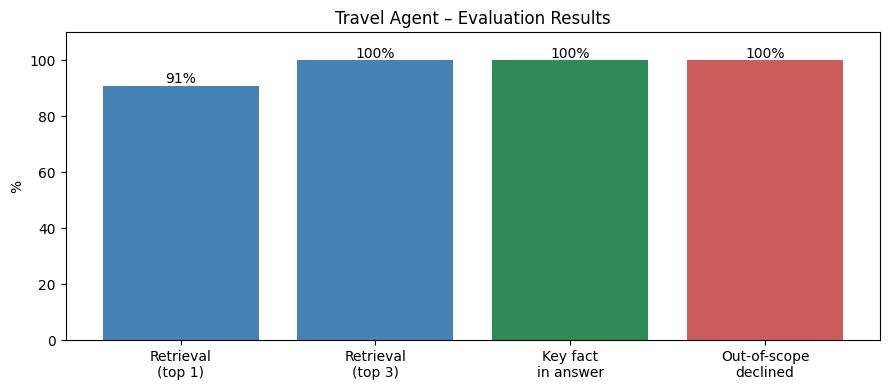

In [ ]:
ins = results[results["Type"] != "Out of scope"]
outs = results[results["Type"] == "Out of scope"]
summary = pd.DataFrame({
    "Measure": ["Retrieval accuracy (correct entry ranked 1st)", "Correct entry in top 3",
                "Key fact included in answer", "Out-of-scope questions correctly declined",
                "Average response time (s)"],
    "Result": [f"{ins['Retrieval correct'].sum()}/{len(ins)} ({ins['Retrieval correct'].mean()*100:.0f}%)",
               f"{ins['Expected in top 3'].sum()}/{len(ins)} ({ins['Expected in top 3'].mean()*100:.0f}%)",
               f"{ins['Key fact in answer'].sum()}/{len(ins)} ({ins['Key fact in answer'].mean()*100:.0f}%)",
               f"{outs['Correctly declined'].sum()}/{len(outs)}",
               f"{results['Time (s)'].mean():.2f}"]})
display(summary)
summary.to_csv(output_dir / "task3_summary.csv", index=False)

plt.figure(figsize=(9, 4))
vals = [ins["Retrieval correct"].mean(), ins["Expected in top 3"].mean(),
        ins["Key fact in answer"].mean(), outs["Correctly declined"].mean()]
labels = ["Retrieval\n(top 1)", "Retrieval\n(top 3)", "Key fact\nin answer", "Out-of-scope\ndeclined"]
bars = plt.bar(labels, [v * 100 for v in vals], color=["steelblue", "steelblue", "seagreen", "indianred"])
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f"{v*100:.0f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("%"); plt.title("Travel Agent – Evaluation Results")
plt.tight_layout(); plt.savefig(output_dir / "task3_02_evaluation.png", dpi=150); plt.show()

### 3.3.3 Agent or chatbot?
The agent decides whether to answer, keeps a simple memory (the current city) and uses a tool (knowledge base search), but it follows a fixed pipeline and cannot plan or take actions. It is best described as a retrieval-augmented chatbot with simple agent behaviour. The full evaluation is in report section 4.4.